# Digit recognition
Offline training of the digit classifier (OpenCV SVM) and a k-NN reference, using MNIST. The trained SVM is saved to `../data/models/svm_digits.xml` and loaded by `digits.py` at startup. It only needs to be run once.

## 0. Preparation

In [3]:
# Check the OpenCV version (the lab environment uses 4.8.x)
import cv2
print("OpenCV should be 4.8.x Current version:", cv2.__version__)

# Numerical arrays, file paths and plots
import numpy as np
import os
import matplotlib.pyplot as plt

# Used only to download MNIST
from sklearn.datasets import fetch_openml

OpenCV should be 4.8.x Current version: 4.8.0


## 1. Loading MNIST
MNIST has 70000 handwritten digits of 28x28 pixels, white on black. It is not stored in the repository: it is downloaded from here.

In [2]:
# Download MNIST (the first time it can take a minute)
mnist = fetch_openml("mnist_784", version=1, as_frame=False)

# Every row has 784 values (28x28 pixels): reshape them into images
images = mnist.data.reshape(-1, 28, 28).astype(np.uint8)

# The labels come as text: convert them to integers (0-9)
labels = mnist.target.astype(np.int32)

print("Images:", images.shape, "Labels:", labels.shape)
print("Gray range:", images.min(), "-", images.max())

Images: (70000, 28, 28) Labels: (70000,)
Gray range: 0 - 255


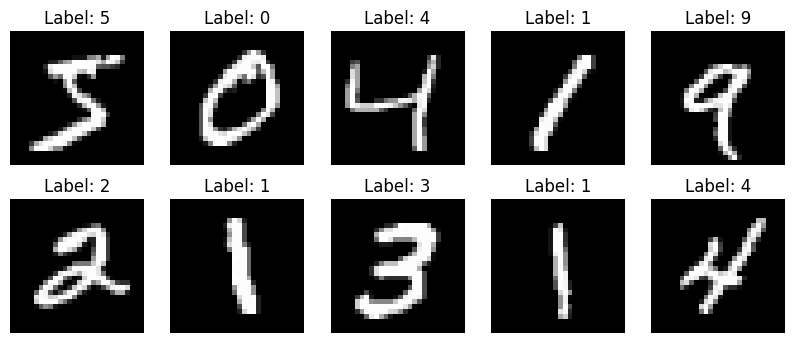

In [5]:
# Show the first 10 images to check that everything was loaded properly
# MNIST digits are WHITE on BLACK, the same as the canvas of main.py (strokes = 255, background = 0)
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, img, label in zip(axes.ravel(), images[:10], labels[:10]):
    ax.imshow(img, cmap="gray")
    ax.set_title(f"Label: {label}")
    ax.axis("off")
plt.show()

## 2. Training and test data
Standard MNIST split: the first 60000 images to train and the last 10000 to evaluate. Only a subset is used for training so the SVM is fast.

In [6]:
# Number of images used to train (increase it later if there is time: more images = slower but better)
n_train = 10000

# OpenCV needs: one sample per row, float32 values and int32 labels
# The gray levels are scaled from 0-255 to 0-1, so C and gamma work well
train_samples = images[:n_train].reshape(n_train, -1).astype(np.float32) / 255.0
train_labels = labels[:n_train]

# The test images are never used to train, only to measure the accuracy
test_samples = images[60000:].reshape(10000, -1).astype(np.float32) / 255.0
test_labels = labels[60000:]

print("Train:", train_samples.shape, "Test:", test_samples.shape)

Train: (10000, 784) Test: (10000, 784)


## 3. SVM
Support Vector Machine with an RBF kernel, as in Practice 5. This is the classifier AirMath will use.

In [7]:
# Create the SVM: C-support classifier with an RBF kernel
svm = cv2.ml.SVM_create()
svm.setType(cv2.ml.SVM_C_SVC)
svm.setKernel(cv2.ml.SVM_RBF)

# C: penalty of the errors. Higher = fits the training data harder (risk of overfitting)
svm.setC(5)

# Gamma: width of the RBF kernel. Higher = more local decision boundaries
svm.setGamma(0.02)

# Stop after 1000 iterations at most
svm.setTermCriteria((cv2.TERM_CRITERIA_MAX_ITER, 1000, 1e-6))

# Train (it can take a minute or two)
svm.train(train_samples, cv2.ml.ROW_SAMPLE, train_labels)

# Predict the test set and compute the accuracy (fraction of digits correctly classified)
_, svm_pred = svm.predict(test_samples)
svm_pred = svm_pred.ravel().astype(np.int32)
svm_accuracy = np.mean(svm_pred == test_labels)
print(f"SVM accuracy: {svm_accuracy * 100:.2f} %")

SVM accuracy: 96.97 %


## 4. k-NN (reference)
It is only used to compare against the SVM in the report. It is not used in AirMath.

In [9]:
# Create the k-Nearest Neighbours classifier and "train" it (it just stores the samples)
knn = cv2.ml.KNearest_create()
knn.train(train_samples, cv2.ml.ROW_SAMPLE, train_labels)

# Each test image takes the most common label among its 3 nearest training images
_, knn_pred, _, _ = knn.findNearest(test_samples, k=3)
knn_pred = knn_pred.ravel().astype(np.int32)
knn_accuracy = np.mean(knn_pred == test_labels)
print(f"k-NN accuracy: {knn_accuracy * 100:.2f} %")

k-NN accuracy: 94.63 %


## 5. SVM confusion matrix
Rows = true digit, columns = predicted digit. A perfect classifier would only have values on the diagonal; everything outside it is an error.

[[ 968    0    3    0    0    2    4    1    2    0]
 [   0 1126    3    1    0    1    3    0    1    0]
 [   5    0 1003    2    2    0    4    9    5    2]
 [   1    0   11  974    1    6    1    6    8    2]
 [   1    0    3    0  959    0    7    1    1   10]
 [   5    1    1   14    3  852    7    1    6    2]
 [   6    3    1    0    4    3  939    0    2    0]
 [   0    8   17    3    8    0    0  981    1   10]
 [   4    0    1    7    6    6    0    4  943    3]
 [   5    6    1    9   17    4    0    7    8  952]]


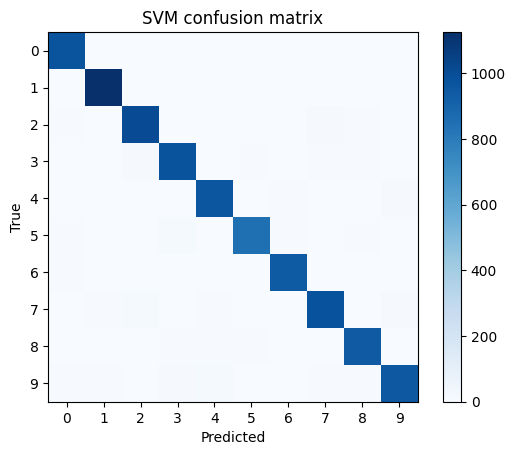

In [10]:
# Count how many times each real digit (row) was predicted as each digit (column)
confusion = np.zeros((10, 10), dtype=np.int32)
np.add.at(confusion, (test_labels, svm_pred), 1)
print(confusion)

# Plot it
plt.imshow(confusion, cmap="Blues")
plt.colorbar()
plt.xticks(range(10))
plt.yticks(range(10))
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("SVM confusion matrix")
plt.show()

## 6. Saving the model
`digits.py` loads this file at startup, so there is no need to train again.

In [11]:
# Save the trained SVM
os.makedirs("../data/models", exist_ok=True)
svm.save("../data/models/svm_digits.xml")

# Check that it can be loaded again and gives the same accuracy
svm_loaded = cv2.ml.SVM_load("../data/models/svm_digits.xml")
_, check_pred = svm_loaded.predict(test_samples)
check_accuracy = np.mean(check_pred.ravel().astype(np.int32) == test_labels)
print(f"Loaded SVM accuracy: {check_accuracy * 100:.2f} %")

Loaded SVM accuracy: 96.97 %
